# EGR 345 Class 17: Random Bode Sketching Examples

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import control
from numpy import sin, cos, tan, pi
from control import TransferFunction as TF

In [5]:
import random_bode_generator as rbg

In [6]:
pip install --upgrade random_bode_generator

Note: you may need to restart the kernel to use updated packages.


In [7]:
rbg.__version__

'1.3.4'

In [8]:
import importlib

In [9]:
importlib.reload(rbg)

<module 'random_bode_generator' from '/opt/homebrew/Cellar/jupyterlab/4.5.6_2/libexec/lib/python3.14/site-packages/random_bode_generator/__init__.py'>

In [10]:
rbg.__version__

'1.3.4'

In [11]:
plt.rcParams['font.size'] = 14

## Bode Sketching Algorithm

- find all poles and zeros
    - convert them to Hz
    - sort them from lowest to highest frequency
- identify the low frequency behavior
    - pure int, pure diff. or neither
        - first or second order int. or diff. possible
- work your way up in frequency
- when you reach a pole or zero, increment or decrement the slope **and** phase
- continue until you are above the highest frequency pole or zero
- double check the high frequency slope and phase
    - slope: $-20(n-m)$ dB/dec
    - phase: $-90^\circ(n-m)$


## Example A1

In [12]:
numA1 = 1
denA1 = [1.        ,4.47720023,0.5323853 ,0.05993002]
GA1 = control.TransferFunction(numA1,denA1)
GA1

TransferFunction(
array([1]),
array([1.        , 4.47720023, 0.5323853 , 0.05993002]),
outputs=1, inputs=1)

### Find Poles and Zeros

Keep in mind that `.poles` and `.zeros` uses radians/second, so we will need to divide by $2 \pi$.

In [13]:
GA1.poles()

array([-4.35819825+0.j        , -0.05950099+0.10104817j,
       -0.05950099-0.10104817j])

For complex roots, we need to find $\omega_n$ (magnitude or resultant) and $\zeta$.

In [14]:
p_A1 = GA1.poles()
p_A1

array([-4.35819825+0.j        , -0.05950099+0.10104817j,
       -0.05950099-0.10104817j])

Pole locations/frequencies in Hz

In [15]:
np.abs(p_A1)/(2*pi)

array([0.6936288 , 0.01866332, 0.01866332])

Find $\zeta$:

$$s = -\zeta \omega_n \pm j \omega_d$$

In [16]:
z_A1 = -np.real(p_A1[1])/np.abs(p_A1[1])
z_A1

np.float64(0.5074058308474682)

In [17]:
GA1.zeros()

array([], dtype=complex128)

Find magnitude at zero frequency:

In [18]:
20*np.log10(GA1(0))

np.complex128(24.447111547392446+0j)

### Hand Sketch

<img src="jupfigs/IMG_0058.PNG" width=800px>

### Check with Python

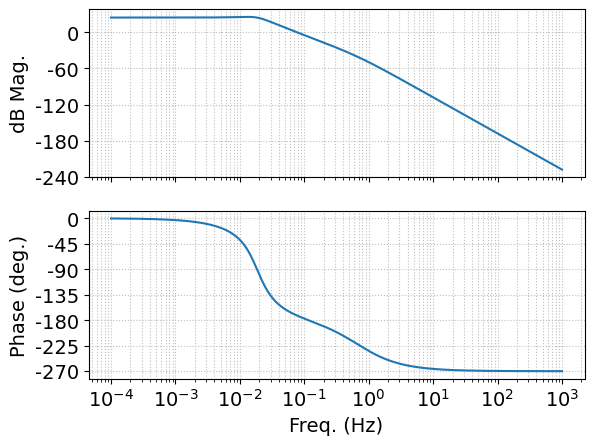

In [19]:
rbg.plot_bode_for_TF(GA1)

In [20]:
np.floor(np.random.rand()*5+1)

np.float64(3.0)

## Example A2

In [21]:
numA2 = [ 1.        ,16.95684616, 6.38078573]
denA2 = [  1.        ,175.08861473, 55.03216241,158.21908191]
GA2 = control.TransferFunction(numA2,denA2)
GA2

TransferFunction(
array([ 1.        , 16.95684616,  6.38078573]),
array([  1.        , 175.08861473,  55.03216241, 158.21908191]),
outputs=1, inputs=1)

## Example 1

In [22]:
num1 = [  1.        ,133.68003066]
den1 = [  1.        , 14.2389736 , 38.64531581,219.58851452]
G1 = control.TransferFunction(num1,den1)
G1

TransferFunction(
array([  1.        , 133.68003066]),
array([  1.        ,  14.2389736 ,  38.64531581, 219.58851452]),
outputs=1, inputs=1)

In [41]:
# .poles and .zeros uses radians so we must divide by 2pi
G1.poles()

array([-12.55394785+0.j        ,  -0.84251287+4.09655496j,
        -0.84251287-4.09655496j])

In [42]:
# for complex roots we need to find wn (magnitude) and zeta
p_1 = G1.poles()
p_1

array([-12.55394785+0.j        ,  -0.84251287+4.09655496j,
        -0.84251287-4.09655496j])

In [43]:
# pole locations in HZ
np.abs(p_1)/(2*np.pi)

array([1.99802286, 0.6656329 , 0.6656329 ])

In [45]:
# find zeta
z_1 = -np.real(p_1[1])/np.abs(p_1[1])
z_1

np.float64(0.20144750605185524)

In [49]:
G1.zeros()/(2*np.pi)

array([-21.27583767+0.j])

In [47]:
20*np.log10(G1(0))

np.complex128(-4.310861685984041+0j)

<img src="jupfigs/example_1_page_2.png" width=800px>

<img src="jupfigs/example_1_page_3.png" width=800px>

<img src="jupfigs/example_1_page_4.png" width=800px>

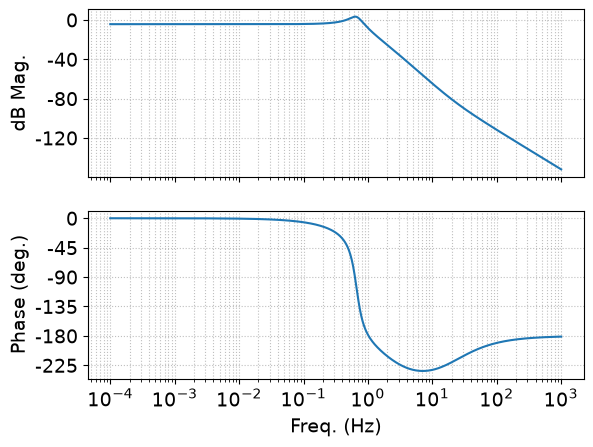

In [48]:
rbg.plot_bode_for_TF(G1)

## Example 2

In [23]:
num2 = [1,0,0]
den2 = [1.00000000e+00,1.18387315e+02,3.79107689e+03,1.43090417e+05,
 5.80167279e+05,1.74448876e+05]
G2 = control.TransferFunction(num2,den2)
G2

TransferFunction(
array([1, 0, 0]),
array([1.00000000e+00, 1.18387315e+02, 3.79107689e+03, 1.43090417e+05,
       5.80167279e+05, 1.74448876e+05]),
outputs=1, inputs=1)

In [24]:
G2.poles()

array([-93.50138403 +0.j        , -10.19788819+35.59873869j,
       -10.19788819-35.59873869j,  -4.16335244 +0.j        ,
        -0.32680214 +0.j        ])

In [25]:
np.abs(G2.poles())/(2*pi)

array([14.88120745,  5.89360687,  5.89360687,  0.66261812,  0.05201218])

## Example 3

In [26]:
num3 = [1.        ,0.14730239,0.02543961]
den3 = [1.00000000e+00,1.68702655e+02,4.73838664e+03,2.04406775e+03,
 2.35805010e+04,0.00000000e+00]
G3 = control.TransferFunction(num3,den3)
G3

TransferFunction(
array([1.        , 0.14730239, 0.02543961]),
array([1.00000000e+00, 1.68702655e+02, 4.73838664e+03, 2.04406775e+03,
       2.35805010e+04, 0.00000000e+00]),
outputs=1, inputs=1)

In [27]:
G3.poles()

array([-1.33246850e+02+0.j        , -3.52005560e+01+0.j        ,
       -1.27624358e-01+2.23855937j, -1.27624358e-01-2.23855937j,
        0.00000000e+00+0.j        ])

In [28]:
G3.zeros()

array([-0.0736512+0.14147477j, -0.0736512-0.14147477j])

In [29]:
np.abs(G3.poles())/(2*pi)

array([21.20689487,  5.60234249,  0.35685633,  0.35685633,  0.        ])

In [30]:
np.abs(G3.zeros())/(2*pi)

array([0.02538489, 0.02538489])

In [31]:
poles3 = G3.poles()

### $\zeta$ for poles

In [32]:
-np.real(poles3)/(np.abs(poles3))

/var/folders/tq/h94svbxs4_j9cprc7h7l745j_y14l7/T/ipykernel_4612/3809560616.py:1: RuntimeWarning: invalid value encountered in divide
  -np.real(poles3)/(np.abs(poles3))


array([1.       , 1.       , 0.0569194, 0.0569194,       nan])

### $\zeta$ for zeros

In [33]:
zeros_4 = G4.zeros()

NameError: name 'G4' is not defined

In [ ]:
-np.real(zeros_4)/(np.abs(zeros_4))

### Pole and Zero Locations

<img src="jupfigs/PXL_20261103_152150618~2.jpg" width=600px>

### Hand Sketch

<img src="jupfigs/PXL_20261103_152154547~2.jpg" width=600px>

#### How to save a Bode from Jupyter

In [34]:
#rbg.plot_bode_for_TF(G3)
#plt.tight_layout()
#plt.savefig("G3_bode_example.png", dpi=300)

### Marked Up Answer for G3

In [35]:
utils_345.find_image_here_or_below("*G3_bode_marked_up.jpg")

<img src="jupfigs/G3_bode_marked_up.jpg" width=800px>


<img src="jupfigs/G3_bode_marked_up.jpg" width=700px>

## Example 4

In [36]:
num4 = [1.        ,0.5893465 ,1.29673289]
den4 = [1.00000000e+00,1.30139596e+02,2.56415269e+03,9.60524184e+04,
 1.80967071e+04,7.80475165e+03]
G4 = control.TransferFunction(num4,den4)
G4

TransferFunction(
array([1.        , 0.5893465 , 1.29673289]),
array([1.00000000e+00, 1.30139596e+02, 2.56415269e+03, 9.60524184e+04,
       1.80967071e+04, 7.80475165e+03]),
outputs=1, inputs=1)

## Example 5

In [37]:
num5 = [  1.        ,356.44557376]
den5 = [ 1.        ,39.12220883,58.32548101, 5.10032787]
G5 = control.TransferFunction(num5,den5)
G5

TransferFunction(
array([  1.        , 356.44557376]),
array([ 1.        , 39.12220883, 58.32548101,  5.10032787]),
outputs=1, inputs=1)

In [38]:
G5.poles()

array([-37.57351868+0.j,  -1.4554234 +0.j,  -0.09326676+0.j])

In [39]:
p_5 = G5.poles()
p_5

array([-37.57351868+0.j,  -1.4554234 +0.j,  -0.09326676+0.j])

In [40]:
np.abs(p_5)/(2*pi)

array([5.98001123, 0.23163783, 0.01484387])

In [41]:
z_5 = -np.real(p_5[1])/np.abs(p_5[1])
z_5

np.float64(1.0)

In [42]:
G5.zeros()

array([-356.44557376+0.j])

In [43]:
20*np.log10(G5(0))

np.complex128(36.887902618209786+0j)

### Hand Sketch

<img src="jupfigs/EGR345_Problem5.jpg" width=600px>

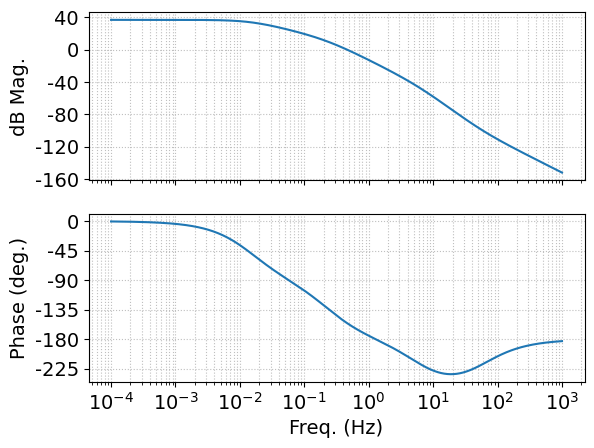

In [44]:
rbg.plot_bode_for_TF(G5)